In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import time
import pandas as pd

# Make sure plots show nicely in Jupyter
%matplotlib inline

IMAGES_DIR = "images/day4"
OUT_DIR_PACKAGE = "outputs/day4/package"
OUT_DIR_SCRATCH = "outputs/day4/scratch"

os.makedirs(OUT_DIR_PACKAGE, exist_ok=True)
os.makedirs(OUT_DIR_SCRATCH, exist_ok=True)

image_paths = sorted(
    glob.glob(os.path.join(IMAGES_DIR, "*.jpg")) +
    glob.glob(os.path.join(IMAGES_DIR, "*.jpeg")) +
    glob.glob(os.path.join(IMAGES_DIR, "*.png")) +
    glob.glob(os.path.join(IMAGES_DIR, "*.webp")) +
    glob.glob(os.path.join(IMAGES_DIR, "*.cms")) +
    glob.glob(os.path.join(IMAGES_DIR, "*.avif"))
)

len(image_paths), image_paths[:3]


(2,
 ['images/day4/2026-yamaha-yzf-r7-1.JPG.webp',
  'images/day4/Ducati-Panigale-V2-Black.jpg'])

In [9]:
def load_image_bgr(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Failed to read image: {path}")
    return img

def bgr2rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show_side_by_side(img1, img2, title1="Package", title2="Scratch"):
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(bgr2rgb(img1))
    plt.title(title1)
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(bgr2rgb(img2))
    plt.title(title2)
    plt.axis("off")
    plt.show()

def time_function(func, *args, repeat=3, **kwargs):
    """Return average time in ms over 'repeat' runs."""
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        _ = func(*args, **kwargs)
        t1 = time.perf_counter()
        times.append((t1 - t0) * 1000.0)
    return float(np.mean(times))


In [4]:
def resize_nearest_scratch(img, new_size):
    """Simple nearest-neighbour resize (H,W,[C])."""
    h, w = img.shape[:2]
    new_h, new_w = new_size
    y_ratio = h / new_h
    x_ratio = w / new_w

    # Build grid of coordinates
    y_idxs = (np.arange(new_h) * y_ratio).astype(int)
    x_idxs = (np.arange(new_w) * x_ratio).astype(int)

    # Clip just in case
    y_idxs = np.clip(y_idxs, 0, h - 1)
    x_idxs = np.clip(x_idxs, 0, w - 1)

    # Use np.ix_ to broadcast
    if img.ndim == 3:
        return img[np.ix_(y_idxs, x_idxs, np.arange(img.shape[2]))]
    else:
        return img[np.ix_(y_idxs, x_idxs)]

def conv2d_scratch(gray, kernel):
    """2D convolution (valid for grayscale)."""
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    padded = np.pad(gray, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    out = np.zeros_like(gray, dtype=np.float32)

    for i in range(gray.shape[0]):
        for j in range(gray.shape[1]):
            region = padded[i:i+kh, j:j+kw]
            out[i, j] = np.sum(region * kernel)

    # Normalize / clip
    out = np.clip(out, 0, 255).astype(np.uint8)
    return out

def conv2d_scratch_color(img, kernel):
    """Apply same kernel to each channel."""
    if img.ndim == 2:
        return conv2d_scratch(img, kernel)
    channels = []
    for c in range(img.shape[2]):
        channels.append(conv2d_scratch(img[..., c], kernel))
    return np.stack(channels, axis=2)


In [10]:
# --- Blur (scratch) - simple box blur 3x3 ---
box_kernel_3 = np.ones((3, 3), dtype=np.float32) / 9.0

def blur_box_scratch(img):
    return conv2d_scratch_color(img, box_kernel_3)


# --- Sharpen (scratch) ---
sharpen_kernel_3 = np.array(
    [[0, -1, 0],
     [-1, 5, -1],
     [0, -1, 0]], dtype=np.float32
)

def sharpen_scratch(img):
    return conv2d_scratch_color(img, sharpen_kernel_3)


# --- Edge detection (scratch using Sobel) ---
sobel_x = np.array(
    [[-1, 0, 1],
     [-2, 0, 2],
     [-1, 0, 1]], dtype=np.float32
)
sobel_y = np.array(
    [[-1, -2, -1],
     [ 0,  0,  0],
     [ 1,  2,  1]], dtype=np.float32
)

def sobel_edge_scratch(img):
    # convert to gray manually
    if img.ndim == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img

    gx = conv2d_scratch(gray, sobel_x)
    gy = conv2d_scratch(gray, sobel_y)

    mag = np.sqrt(gx.astype(np.float32)**2 + gy.astype(np.float32)**2)
    mag = np.clip(mag / mag.max() * 255, 0, 255).astype(np.uint8)
    # return as 3-channel to visually match others
    return cv2.cvtColor(mag, cv2.COLOR_GRAY2BGR)


# --- Colorspace conversion (scratch) ---
def bgr_to_gray_scratch(img):
    # BGR to Gray using standard coefficients
    b, g, r = img[..., 0], img[..., 1], img[..., 2]
    gray = 0.114 * b + 0.587 * g + 0.299 * r
    gray = np.clip(gray, 0, 255).astype(np.uint8)
    return gray

def bgr_to_rgb_scratch(img):
    return img[..., ::-1]  # swap channels


In [11]:
def resize_cv(img, new_size=(256, 256)):
    return cv2.resize(img, new_size, interpolation=cv2.INTER_LINEAR)

def blur_cv(img, ksize=(3, 3)):
    return cv2.GaussianBlur(img, ksize, sigmaX=0)

def sharpen_cv(img):
    kernel = np.array(
        [[0, -1, 0],
         [-1, 5, -1],
         [0, -1, 0]], dtype=np.float32
    )
    return cv2.filter2D(img, -1, kernel)

def edge_cv(img):
    # Canny on grayscale then convert back to 3-channel for comparison
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, threshold1=100, threshold2=200)
    return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

def colorspace_cv_bgr2gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def colorspace_cv_bgr2hsv(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Example extra FILTER: emboss
emboss_kernel = np.array(
    [[-2, -1, 0],
     [-1,  1, 1],
     [ 0,  1, 2]], dtype=np.float32
)

def emboss_cv(img):
    return cv2.filter2D(img, -1, emboss_kernel)

def emboss_scratch(img):
    return conv2d_scratch_color(img, emboss_kernel)


In [12]:
results = []

target_size = (256, 256)

for path in image_paths[:10]:   # ensure we use 10 images
    filename = os.path.splitext(os.path.basename(path))[0]
    img = load_image_bgr(path)

    # ---------------- RESIZE ----------------
    pkg_time = time_function(resize_cv, img, target_size)
    scratch_time = time_function(resize_nearest_scratch, img, target_size)
    results.append(["resize", "package", filename, pkg_time])
    results.append(["resize", "scratch", filename, scratch_time])

    resized_pkg = resize_cv(img, target_size)
    resized_scr = resize_nearest_scratch(img, target_size)
    cv2.imwrite(os.path.join(OUT_DIR_PACKAGE, f"{filename}_resize_pkg.png"), resized_pkg)
    cv2.imwrite(os.path.join(OUT_DIR_SCRATCH, f"{filename}_resize_scr.png"), resized_scr)

    # ---------------- BLUR ----------------
    pkg_time = time_function(blur_cv, img, (5, 5))
    scratch_time = time_function(blur_box_scratch, img)
    results.append(["blur", "package", filename, pkg_time])
    results.append(["blur", "scratch", filename, scratch_time])

    blur_pkg = blur_cv(img, (5, 5))
    blur_scr = blur_box_scratch(img)
    cv2.imwrite(os.path.join(OUT_DIR_PACKAGE, f"{filename}_blur_pkg.png"), blur_pkg)
    cv2.imwrite(os.path.join(OUT_DIR_SCRATCH, f"{filename}_blur_scr.png"), blur_scr)

    # ---------------- SHARPEN ----------------
    pkg_time = time_function(sharpen_cv, img)
    scratch_time = time_function(sharpen_scratch, img)
    results.append(["sharpen", "package", filename, pkg_time])
    results.append(["sharpen", "scratch", filename, scratch_time])

    sharp_pkg = sharpen_cv(img)
    sharp_scr = sharpen_scratch(img)
    cv2.imwrite(os.path.join(OUT_DIR_PACKAGE, f"{filename}_sharpen_pkg.png"), sharp_pkg)
    cv2.imwrite(os.path.join(OUT_DIR_SCRATCH, f"{filename}_sharpen_scr.png"), sharp_scr)

    # ---------------- EDGE DETECTION ----------------
    pkg_time = time_function(edge_cv, img)
    scratch_time = time_function(sobel_edge_scratch, img)
    results.append(["edge", "package", filename, pkg_time])
    results.append(["edge", "scratch", filename, scratch_time])

    edge_pkg = edge_cv(img)
    edge_scr = sobel_edge_scratch(img)
    cv2.imwrite(os.path.join(OUT_DIR_PACKAGE, f"{filename}_edge_pkg.png"), edge_pkg)
    cv2.imwrite(os.path.join(OUT_DIR_SCRATCH, f"{filename}_edge_scr.png"), edge_scr)

    # ---------------- COLORSPACE CONVERSION ----------------
    pkg_time = time_function(colorspace_cv_bgr2gray, img)
    scratch_time = time_function(bgr_to_gray_scratch, img)
    results.append(["bgr2gray", "package", filename, pkg_time])
    results.append(["bgr2gray", "scratch", filename, scratch_time])

    gray_pkg = colorspace_cv_bgr2gray(img)
    gray_scr = bgr_to_gray_scratch(img)
    cv2.imwrite(os.path.join(OUT_DIR_PACKAGE, f"{filename}_bgr2gray_pkg.png"), gray_pkg)
    cv2.imwrite(os.path.join(OUT_DIR_SCRATCH, f"{filename}_bgr2gray_scr.png"), gray_scr)

    # ---------------- FILTER (EMBOSS) ----------------
    pkg_time = time_function(emboss_cv, img)
    scratch_time = time_function(emboss_scratch, img)
    results.append(["emboss", "package", filename, pkg_time])
    results.append(["emboss", "scratch", filename, scratch_time])

    emboss_pkg = emboss_cv(img)
    emboss_scr = emboss_scratch(img)
    cv2.imwrite(os.path.join(OUT_DIR_PACKAGE, f"{filename}_emboss_pkg.png"), emboss_pkg)
    cv2.imwrite(os.path.join(OUT_DIR_SCRATCH, f"{filename}_emboss_scr.png"), emboss_scr)

len(results)


24

In [13]:
df_times = pd.DataFrame(results, columns=["operation", "method", "image", "time_ms"])
display(df_times.head())

# Average over 10 images
df_summary = (
    df_times
    .groupby(["operation", "method"])["time_ms"]
    .mean()
    .reset_index()
    .sort_values(by=["operation", "method"])
)

display(df_summary)

# Save for Week-Report
df_times.to_csv("day4_time_details.csv", index=False)
df_summary.to_csv("day4_time_summary.csv", index=False)


,operation,method,image,time_ms
0,resize,package,2026-yamaha-yzf-r7-1.JPG,0.174111
1,resize,scratch,2026-yamaha-yzf-r7-1.JPG,1.279861
2,blur,package,2026-yamaha-yzf-r7-1.JPG,0.350028
3,blur,scratch,2026-yamaha-yzf-r7-1.JPG,3981.020014
4,sharpen,package,2026-yamaha-yzf-r7-1.JPG,0.898194


,operation,method,time_ms
0,bgr2gray,package,0.080021
1,bgr2gray,scratch,2.895632
2,blur,package,0.325840
3,blur,scratch,4284.029812
4,edge,package,1.053597
5,edge,scratch,2839.395514
6,emboss,package,1.232965
7,emboss,scratch,4283.969479
8,resize,package,0.146472
9,resize,scratch,1.033250


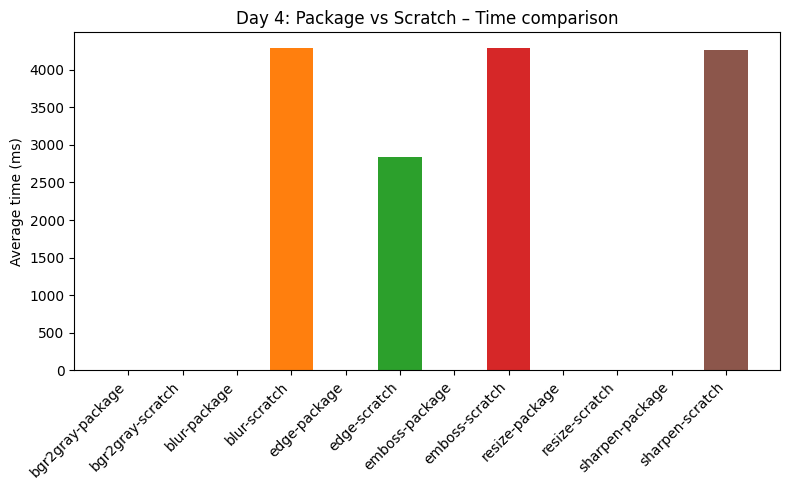

In [14]:
plt.figure(figsize=(8, 5))

for op in df_summary["operation"].unique():
    subset = df_summary[df_summary["operation"] == op]
    plt.bar(
        [f"{op}-{m}" for m in subset["method"]],
        subset["time_ms"].values
    )

plt.xticks(rotation=45, ha="right")
plt.ylabel("Average time (ms)")
plt.title("Day 4: Package vs Scratch – Time comparison")
plt.tight_layout()
plt.show()
